# Bài 3 · Tán xạ Rutherford
*Episode 3 · Rutherford scattering*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JasonDE03/sophon/blob/main/lab/03_rutherford.ipynb)

Từ quỹ đạo của một hạt alpha đến quy luật tán xạ trên lá vàng: hãy chạy lần lượt các ô để so sánh tính toán, Monte Carlo và số đo của Geiger–Marsden.
*From one alpha particle's orbit to the scattering law for gold foil: run the cells in order to compare calculations, Monte Carlo, and Geiger–Marsden's measurements.*

## 1. Hạt alpha đến gần hạt nhân tới đâu?
*How close does an alpha particle get to the nucleus?*

Dùng MeV và fm ($1$ fm $=10^{-15}$ m). Đổi $K=e^2/(4\pi\varepsilon_0)$ từ J·m sang MeV·fm bằng các hằng số của SciPy, được khoảng $1{,}439964$ MeV·fm. Với hạt alpha mang điện tích $2e$, vàng có $Z=79$, và động năng ban đầu $E=7{,}7$ MeV, bảo toàn năng lượng cho khoảng cách gần nhất khi bay thẳng vào tâm:
*Use MeV and fm ($1$ fm $=10^{-15}$ m). Convert $K=e^2/(4\pi\varepsilon_0)$ from J·m to MeV·fm using SciPy's constants, giving about $1.439964$ MeV·fm. For an alpha particle of charge $2e$, gold with $Z=79$, and initial kinetic energy $E=7.7$ MeV, energy conservation gives the head-on distance of closest approach:*

$$E=\frac{2ZK}{d},\qquad d=\frac{2ZK}{E}\approx29{,}55\ \mathrm{fm},\qquad
R_{\mathrm{Au}}\approx1{,}2\,A^{1/3}\ \mathrm{fm}\approx7\ \mathrm{fm}\quad(A=197).$$

Ngay cả khi bay thẳng vào tâm, hạt alpha cũng quay lại trước khi chạm hạt nhân. Ta dùng mô hình Coulomb thuần túy, hạt nhân đứng yên, bỏ qua che chắn electron, mất năng lượng và tán xạ nhiều lần; đây là mô hình cho một lần tán xạ ở góc lớn.
*Even head-on, the alpha turns back before touching the nucleus. Use pure Coulomb scattering with a stationary nucleus, neglecting electron screening, energy loss, and multiple scattering; this models a single large-angle encounter.*

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import elementary_charge as e, epsilon_0
from scipy.integrate import solve_ivp
from io import StringIO

# e**2 / (4*pi*epsilon_0) is in J m; 1 MeV = 1e6*e J, 1 m = 1e15 fm.
K = e**2 / (4 * np.pi * epsilon_0) / (1e6 * e) * 1e15
assert abs(K - 1.439964) < 1e-6
Z, A = 79, 197
E = 7.7  # Incident kinetic energy at infinity, in MeV.
coupling = 2 * Z * K  # Repulsive potential U(r) = coupling / r, in MeV.
d = coupling / E
nuclear_radius = 1.2 * A**(1 / 3)  # Empirical nuclear-radius estimate, in fm.
assert abs(d - 29.55) < 0.01
assert abs(nuclear_radius - 7.0) < 0.1
assert d > 4 * nuclear_radius
print(f"K = {K:.9f} MeV fm")
print(f"Alpha on gold at {E:.1f} MeV: d = {d:.5f} fm")
print(f"Gold nuclear radius = {nuclear_radius:.3f} fm; d/R = {d/nuclear_radius:.3f}")

K = 1.439964547 MeV fm
Alpha on gold at 7.7 MeV: d = 29.54732 fm
Gold nuclear radius = 6.982 fm; d/R = 4.232


## 2. Từ lực đẩy đến góc lệch
*From repulsion to the deflection angle*

Khoảng nhắm lệch (tham số va chạm) $b$ là khoảng cách vuông góc từ đường bay tới ở rất xa đến tâm hạt nhân. Với $\tau=v_\infty t$ tính bằng fm và $\mathbf u=\mathbf v/v_\infty$, phương trình Newton trở thành:
*The impact parameter $b$ is the perpendicular distance from the distant incoming path to the nuclear centre. With $\tau=v_\infty t$ in fm and $\mathbf u=\mathbf v/v_\infty$, Newton's equation becomes:*

$$\frac{d\mathbf r}{d\tau}=\mathbf u,\qquad
\frac{d\mathbf u}{d\tau}=\frac{d}{2}\frac{\mathbf r}{r^3},\qquad
\theta=2\arctan\frac{d}{2b}.$$

Tích phân bằng `solve_ivp` từ $x=-10^5$ fm đến khi hạt ra xa cùng bán kính. Vận tốc đầu được chọn để tổng năng lượng bằng $E$; sai số do thay khoảng cách vô hạn bằng hữu hạn nằm trong phép kiểm tra $0{,}2^\circ$. Trên hình chỉ vẽ vùng gần hạt nhân; vòng tròn xám có bán kính thật theo tỉ lệ.
*Integrate with `solve_ivp` from $x=-10^5$ fm until the particle recedes to the same radius. Set the initial speed so total energy equals $E$; the $0.2^\circ$ check includes the finite-distance approximation. Only the region near the nucleus is shown; the grey circle has the nuclear radius to scale.*

  b (fm)   Numerical (deg)   Rutherford (deg)   Error (deg)
       5        142.609377         142.604237      0.005141
      10        111.821269         111.813411      0.007859
      20         72.913403          72.905312      0.008090
      40         40.548067          40.542567      0.005500
      80         20.928974          20.925957      0.003017


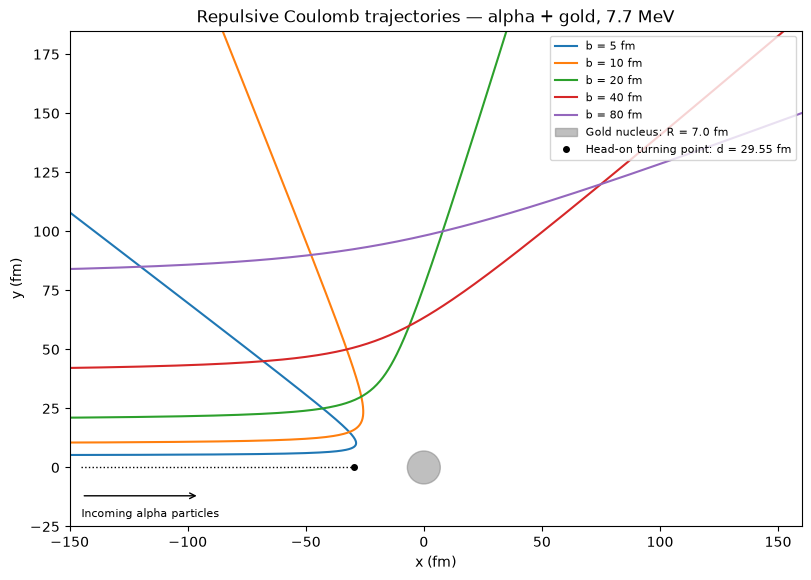

Largest deflection error = 0.008090 deg (limit: 0.2 deg)


In [2]:
def coulomb_motion(tau, state):
    """State = (x, y, ux, uy); positions and tau in fm, u = v/v_infinity."""
    position = state[:2]
    acceleration = (d / 2) * position / np.linalg.norm(position)**3
    return [*state[2:], *acceleration]


impact_parameters = np.array([5, 10, 20, 40, 80], dtype=float)
start_distance = 1e5  # Large compared with every impact parameter and d.
trajectories = []
deflection_errors = []
print(f"{'b (fm)':>8} {'Numerical (deg)':>17} {'Rutherford (deg)':>18} {'Error (deg)':>13}")
for b in impact_parameters:
    start_radius = np.hypot(start_distance, b)
    initial_speed = np.sqrt(1 - d / start_radius)

    def outgoing_radius(tau, state):
        return np.linalg.norm(state[:2]) - start_radius

    outgoing_radius.direction = 1  # Ignore the inward crossing at the start.
    outgoing_radius.terminal = True
    solution = solve_ivp(
        coulomb_motion, (0, 3 * start_distance),
        [-start_distance, b, initial_speed, 0],
        method="DOP853", events=outgoing_radius, dense_output=True,
        rtol=1e-10, atol=1e-11,
    )
    assert solution.success and len(solution.t_events[0]) == 1
    theta_numerical = np.arctan2(solution.y[3, -1], solution.y[2, -1])
    theta_exact = 2 * np.arctan2(d / 2, b)
    error_deg = abs(np.degrees(theta_numerical - theta_exact))
    assert error_deg < 0.2
    deflection_errors.append(error_deg)

    # Total energy / E = u**2 + d/r; check conservation along the entire orbit.
    energy_ratio = np.sum(solution.y[2:]**2, axis=0) + d / np.linalg.norm(solution.y[:2], axis=0)
    assert np.max(np.abs(energy_ratio - 1)) < 1e-8
    print(f"{b:8.0f} {np.degrees(theta_numerical):17.6f} {np.degrees(theta_exact):18.6f} {error_deg:13.6f}")
    trajectories.append(solution)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
for b, solution in zip(impact_parameters, trajectories):
    # Subdivide adaptive steps for smooth curves without a huge uniform time grid.
    times = np.concatenate([np.linspace(left, right, 8)
                            for left, right in zip(solution.t[:-1], solution.t[1:])])
    orbit = solution.sol(times)
    ax.plot(orbit[0], orbit[1], label=f"b = {b:.0f} fm")
ax.add_patch(plt.Circle((0, 0), nuclear_radius, color="grey", alpha=0.5,
                        label=f"Gold nucleus: R = {nuclear_radius:.1f} fm"))
ax.plot([-145, -d], [0, 0], color="black", ls=":", lw=1)
ax.plot(-d, 0, "ko", ms=4, label=f"Head-on turning point: d = {d:.2f} fm")
ax.annotate("", xy=(-95, -12), xytext=(-145, -12),
            arrowprops={"arrowstyle": "->"})
ax.text(-145, -21, "Incoming alpha particles", fontsize=8)
ax.set(xlim=(-150, 160), ylim=(-25, 185), aspect="equal",
       xlabel="x (fm)", ylabel="y (fm)", title=f"Repulsive Coulomb trajectories — alpha + gold, {E:.1f} MeV")
ax.legend(loc="upper right", fontsize=8)
plt.show()
print(f"Largest deflection error = {max(deflection_errors):.6f} deg (limit: 0.2 deg)")

## 3. Lá mỏng Monte Carlo: một triệu hạt alpha
*Monte Carlo thin foil: one million alpha particles*

Đây là **mô phỏng**, không phải dữ liệu thí nghiệm: mỗi hạt gặp một hạt nhân, với $b^2$ phân bố đều trên đĩa bán kính $b_{\max}=200$ fm. Vì diện tích vành khăn là $2\pi b\,db$, phải lấy $b=b_{\max}\sqrt{U}$ với $U$ đều trên $[0,1)$, thay vì lấy $b$ đều. Mô hình này kiểm tra dạng góc của tiết diện tán xạ, chưa mô tả độ dày lá vàng hay xác suất tán xạ tuyệt đối.
*This is a **simulation**, not experimental data: each particle encounters one nucleus, with $b^2$ uniform over a disc of radius $b_{\max}=200$ fm. The annular area is $2\pi b\,db$, so sample $b=b_{\max}\sqrt{U}$ with $U$ uniform on $[0,1)$, rather than uniform $b$. This tests the angular shape of the scattering cross section, without modelling foil thickness or absolute scattering probability.*

Chia số đếm cho góc khối của từng bin $\Delta\Omega=2\pi(\cos\theta_1-\cos\theta_2)$ để so với công thức Rutherford. Với $n$ hạt trên đĩa:
*Divide counts by each bin's solid angle $\Delta\Omega=2\pi(\cos\theta_1-\cos\theta_2)$ to compare with Rutherford's formula. For $n$ particles on the disc:*

$$\frac{d\sigma}{d\Omega}=\frac{d^2}{16\sin^4(\theta/2)},\qquad
\frac{dN}{d\Omega}=\frac{n}{\pi b_{\max}^2}\frac{d\sigma}{d\Omega},\qquad
\theta_{\min}=2\arctan\frac{d}{2b_{\max}}.$$

Dùng trung bình lý thuyết chính xác trên từng bin, không thay bằng giá trị tại tâm bin. Sai số số đếm là $\sigma_i=\sqrt{np_i(1-p_i)}$ cho tổng số hạt cố định; kiểm tra năm bin định trước trong khoảng $3\sigma$.
*Use the exact theoretical average over each bin, rather than its midpoint value. Count uncertainty is $\sigma_i=\sqrt{np_i(1-p_i)}$ for a fixed total sample; check five preselected bins within $3\sigma$.*

Particles = 1,000,000; b_max = 200 fm; theta_min = 8.449 deg
    Angle bin (deg)    Counts    Expected  Pull (sigma)  Checked
   8.45 -   10.00    287457   287126.00         0.732  
  10.00 -   15.00    397940   398057.03        -0.239  yes
  15.00 -   20.00    139314   139316.29        -0.007  
  20.00 -   30.00     98963    99501.06        -1.798  yes
  30.00 -   40.00     34895    34810.30         0.462  
  40.00 -   50.00     16329    16095.24         1.858  
  50.00 -   60.00      8705     8724.50        -0.210  yes
  60.00 -   75.00      7131     7102.24         0.343  
  75.00 -   90.00      3762     3810.82        -0.792  
  90.00 -  105.00      2193     2243.77        -1.073  yes
 105.00 -  120.00      1401     1393.91         0.190  
 120.00 -  135.00       922      882.65         1.325  
 135.00 -  150.00       558      544.43         0.582  yes
 150.00 -  165.00       332      297.19         2.020  
 165.00 -  180.00        98       94.57         0.352  


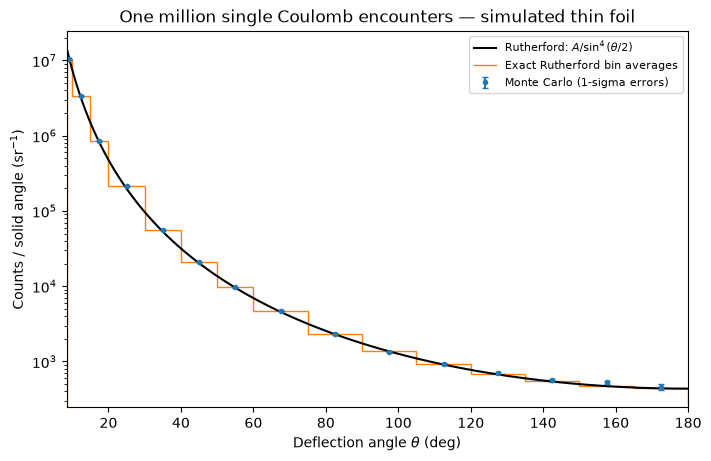

In [3]:
rng = np.random.default_rng(1911)
n_particles = 1_000_000
b_max = 200.0  # fm; a sampling cutoff, not an atomic or nuclear radius.
b_samples = b_max * np.sqrt(rng.random(n_particles))
theta_samples = 2 * np.arctan2(d / 2, b_samples)
theta_min = 2 * np.arctan2(d / 2, b_max)
edges = np.r_[theta_min, np.deg2rad([10, 15, 20, 30, 40, 50, 60, 75, 90, 105, 120, 135, 150, 165, 180])]
assert np.all(np.diff(edges) > 0)
counts, _ = np.histogram(theta_samples, bins=edges)
solid_angle = 2 * np.pi * (np.cos(edges[:-1]) - np.cos(edges[1:]))
centres_deg = np.degrees((edges[:-1] + edges[1:]) / 2)

# Exact integrated Rutherford prediction: each angular bin maps to an annulus.
b_edges = np.minimum(b_max, d / (2 * np.tan(edges / 2)))
probability = (b_edges[:-1]**2 - b_edges[1:]**2) / b_max**2
expected = n_particles * probability
count_sigma = np.sqrt(n_particles * probability * (1 - probability))
assert counts.sum() == n_particles
assert np.isclose(probability.sum(), 1)
pulls = (counts - expected) / count_sigma
checked_bins = np.array([1, 3, 6, 9, 12])  # Chosen before inspecting the sample.
assert np.all(expected[checked_bins] > 25)
assert np.all(np.abs(pulls[checked_bins]) < 3), "Monte Carlo differs by more than 3 sigma."
print(f"Particles = {n_particles:,}; b_max = {b_max:.0f} fm; theta_min = {np.degrees(theta_min):.3f} deg")
print(f"{'Angle bin (deg)':>19} {'Counts':>9} {'Expected':>11} {'Pull (sigma)':>13}  Checked")
for i, (left, right) in enumerate(zip(np.degrees(edges[:-1]), np.degrees(edges[1:]))):
    print(f"{left:7.2f} - {right:7.2f} {counts[i]:9d} {expected[i]:11.2f} {pulls[i]:13.3f}  {'yes' if i in checked_bins else ''}")

fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
grid = np.linspace(theta_min, np.pi, 800)
coefficient = n_particles * d**2 / (16 * np.pi * b_max**2)
ax.plot(np.degrees(grid), coefficient / np.sin(grid / 2)**4,
        color="black", label=r"Rutherford: $A/\sin^4(\theta/2)$")
ax.stairs(expected / solid_angle, np.degrees(edges), color="tab:orange",
          label="Exact Rutherford bin averages")
ax.errorbar(centres_deg, counts / solid_angle, yerr=count_sigma / solid_angle,
            fmt="o", ms=3, capsize=2, label="Monte Carlo (1-sigma errors)")
ax.set(yscale="log", xlim=(np.degrees(theta_min), 180),
       xlabel=r"Deflection angle $\theta$ (deg)", ylabel=r"Counts / solid angle (sr$^{-1}$)",
       title="One million single Coulomb encounters — simulated thin foil")
ax.legend(fontsize=8)
plt.show()

## 4. Dữ liệu thật: Geiger và Marsden (1913)
*Real data: Geiger and Marsden (1913)*

Bảng II, trang in 610 (trang 7 của [bản quét Saarland](https://grundpraktikum.physik.uni-saarland.de/gpalt/Anleitungen/Ergaenzungen/J1_Papers/Rutherford%20-%20Geiger_Marsden.pdf#page=7)), trong bài *The laws of deflexion of α particles through large angles*, Phil. Mag. 25, 604–623, có cả bạc và vàng. Các số dưới đây được chép trực tiếp từ bản quét, giữ dấu chấm giữa làm dấu thập phân như bản in. $N$ đã được hiệu chỉnh, không phải số đếm thô để gán sai số $\sqrt{N}$.
*Table II, printed page 610 (page 7 of the [Saarland scan](https://grundpraktikum.physik.uni-saarland.de/gpalt/Anleitungen/Ergaenzungen/J1_Papers/Rutherford%20-%20Geiger_Marsden.pdf#page=7)), in The laws of deflexion of α particles through large angles, Phil. Mag. 25, 604–623, includes silver and gold. The numbers below are transcribed directly from the scan, retaining its decimal middle dots. $N$ is corrected, not a raw count to which $\sqrt{N}$ errors can be assigned.*

Hai khối là hai loạt đo với chuẩn hóa khác nhau, cần fit riêng. Cột tỉ số là $N/\csc^4(\theta/2)=N\sin^4(\theta/2)$. Ta khớp $N=A/\sin^4(\theta/2)$ trong không gian log, cho các điểm trọng số bằng nhau; đây là so sánh hình dạng, không phải phép fit có mô hình sai số thí nghiệm. Tỉ số chỉ gần hằng số: loạt thứ nhất có xu hướng tăng về góc nhỏ, như tác giả đã lưu ý.
*The two blocks are separate measurement series with different normalizations and must be fitted separately. The ratio column is $N/\csc^4(\theta/2)=N\sin^4(\theta/2)$. Fit $N=A/\sin^4(\theta/2)$ in log space with equal point weights; this compares shapes without an experimental uncertainty model. The ratio is only roughly constant: the first series rises towards small angles, as the authors noted.*

In [4]:
# H. Geiger and E. Marsden, Phil. Mag. 25, 604-623 (1913).
# Table II, printed p. 610, PDF p. 7; both complete blocks, columns I-VI.
# Visually transcribed from the original scan (not inferred from the formula):
# https://grundpraktikum.physik.uni-saarland.de/gpalt/Anleitungen/Ergaenzungen/J1_Papers/Rutherford%20-%20Geiger_Marsden.pdf#page=7
# Columns: angle (deg), cosec^4(angle/2), silver N, silver ratio, gold N, gold ratio.
# Ratio = N / cosec^4(angle/2). Printed rounding and decimal middle dots retained.
# "..." denotes the two blank silver entries at 5 degrees; no value is supplied.
series_1_table = """
150   1·15      22·2    19·3    33·1    28·8
135   1·38      27·4    19·8    43·0    31·2
120   1·79      33·0    18·4    51·9    29·0
105   2·53      47·3    18·7    69·5    27·5
75    7·25      136     18·8    211     29·1
60    16·0      320     20·0    477     29·8
45    46·6      989     21·2    1435    30·8
37·5  93·7      1760    18·8    3300    35·3
30    223       5260    23·6    7800    35·0
22·5  690       20300   29·4    27300   39·6
15    3445      105400  30·6    132000  38·4
"""
series_2_table = """
30    223       5·3     0·024   3·1     0·014
22·5  690       16·6    0·024   8·4     0·012
15    3445      93·0    0·027   48·2    0·014
10    17330     508     0·029   200     0·0115
7·5   54650     1710    0·031   607     0·011
5     276300    ...     ...     3320    0·012
"""

historical_series = []
for name, table in [("Series 1", series_1_table), ("Series 2", series_2_table)]:
    values = np.loadtxt(StringIO(table.replace("·", ".").replace("...", "nan")))
    historical_series.append((name, values))
    print(f"{name}: angle | cosec^4 | silver N | silver N/cosec^4 | gold N | gold N/cosec^4")
    print(table.strip(), "\n")
    for count_column, ratio_column in [(2, 3), (4, 5)]:
        present = np.isfinite(values[:, count_column])
        # Allow the printed ratios' two-significant-digit rounding (e.g. 508/17330 -> 0.029).
        assert np.allclose(values[present, count_column] / values[present, 1],
                           values[present, ratio_column], rtol=0.02)
assert historical_series[0][1].shape == (11, 6)
assert historical_series[1][1].shape == (6, 6)
assert np.isnan(historical_series[1][1][-1, 2:4]).all()

Series 1: angle | cosec^4 | silver N | silver N/cosec^4 | gold N | gold N/cosec^4
150   1·15      22·2    19·3    33·1    28·8
135   1·38      27·4    19·8    43·0    31·2
120   1·79      33·0    18·4    51·9    29·0
105   2·53      47·3    18·7    69·5    27·5
75    7·25      136     18·8    211     29·1
60    16·0      320     20·0    477     29·8
45    46·6      989     21·2    1435    30·8
37·5  93·7      1760    18·8    3300    35·3
30    223       5260    23·6    7800    35·0
22·5  690       20300   29·4    27300   39·6
15    3445      105400  30·6    132000  38·4 

Series 2: angle | cosec^4 | silver N | silver N/cosec^4 | gold N | gold N/cosec^4
30    223       5·3     0·024   3·1     0·014
22·5  690       16·6    0·024   8·4     0·012
15    3445      93·0    0·027   48·2    0·014
10    17330     508     0·029   200     0·0115
7·5   54650     1710    0·031   607     0·011
5     276300    ...     ...     3320    0·012 



Series 1, Silver: A = 21.369; N*sin^4 range = 18.562 to 30.594; max/min = 1.648
Series 1, Gold: A = 32.001; N*sin^4 range = 27.533 to 39.546; max/min = 1.436
Series 2, Silver: A = 0.026928; N*sin^4 range = 0.023783 to 0.031289; max/min = 1.316
Series 2, Gold: A = 0.012407; N*sin^4 range = 0.011107 to 0.013991; max/min = 1.260


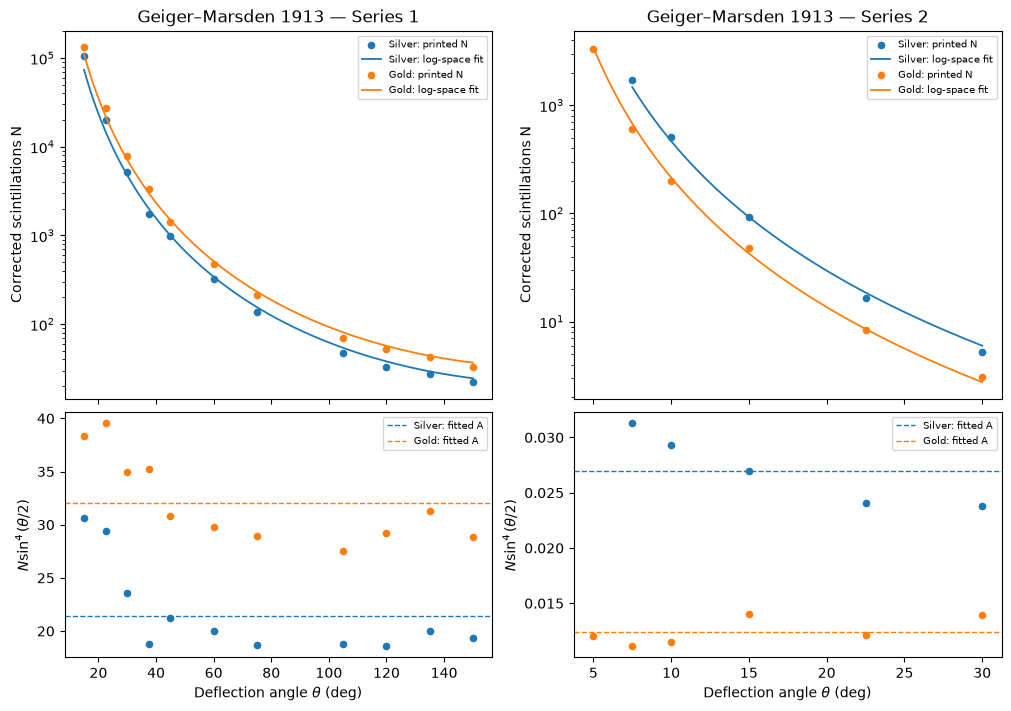

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex="col",
                         gridspec_kw={"height_ratios": [3, 2]}, layout="constrained")
for column, (name, values) in enumerate(historical_series):
    counts_ax, ratio_ax = axes[:, column]
    for metal, count_column, color in [("Silver", 2, "tab:blue"), ("Gold", 4, "tab:orange")]:
        present = np.isfinite(values[:, count_column])
        angles_deg = values[present, 0]
        measured = values[present, count_column]
        sin_fourth = np.sin(np.deg2rad(angles_deg) / 2)**4
        scaled_counts = measured * sin_fourth
        # Closed-form least-squares amplitude in log space, one per metal and series.
        amplitude = np.exp(np.mean(np.log(scaled_counts)))
        grid_deg = np.linspace(angles_deg.min(), angles_deg.max(), 500)
        prediction = amplitude / np.sin(np.deg2rad(grid_deg) / 2)**4
        counts_ax.scatter(angles_deg, measured, color=color, s=20, label=f"{metal}: printed N")
        counts_ax.plot(grid_deg, prediction, color=color, lw=1.3, label=f"{metal}: log-space fit")
        ratio_ax.scatter(angles_deg, scaled_counts, color=color, s=20)
        ratio_ax.axhline(amplitude, color=color, ls="--", lw=1, label=f"{metal}: fitted A")
        print(f"{name}, {metal}: A = {amplitude:.5g}; N*sin^4 range = "
              f"{scaled_counts.min():.5g} to {scaled_counts.max():.5g}; "
              f"max/min = {scaled_counts.max()/scaled_counts.min():.3f}")
    counts_ax.set(yscale="log", ylabel="Corrected scintillations N", title=f"Geiger–Marsden 1913 — {name}")
    counts_ax.legend(fontsize=7)
    ratio_ax.set(xlabel=r"Deflection angle $\theta$ (deg)", ylabel=r"$N\sin^4(\theta/2)$")
    ratio_ax.legend(fontsize=7)
plt.show()

## 5. Thử thêm / *Try this*

- Giảm `E` từ $7{,}7$ xuống $5$ MeV rồi chạy lại: $d$, góc lệch và tiết diện tán xạ thay đổi ra sao? Cập nhật các phép kiểm tra giá trị tham chiếu ở phần 1.
  *Lower `E` from $7.7$ to $5$ MeV and rerun: how do $d$, the deflection angles, and the scattering cross section change? Update the reference-value checks in section 1.*
- Thử nhôm với `Z = 13`, `A = 27`: so sánh $d/R$ và số hạt lệch trên $90^\circ$ với vàng. Cập nhật nhãn và các phép kiểm tra riêng cho vàng.
  *Try aluminium with `Z = 13`, `A = 27`: compare $d/R$ and counts above $90^\circ$ with gold. Update labels and checks specific to gold.*
- Giảm `n_particles` xuống $10^4$: sai số tương đối ở góc lớn tăng thế nào? Thử thêm seed khác và nhớ rằng kiểm tra $3\sigma$ đôi khi có thể không đạt do dao động thống kê.
  *Reduce `n_particles` to $10^4$: how do relative uncertainties at large angles grow? Try other seeds and remember that a $3\sigma$ check can occasionally fail through statistical fluctuations.*